# Task 4 · Sentiment Analysis

This notebook classifies tweets about six US airlines as positive, neutral, or negative. The file is the Twitter US Airline Sentiment set: 14,640 tweets collected in February 2015.

Two models are trained on the same features. The useful question is not only which one scores higher, but which mistakes it still makes.


## 1. Setup


In [1]:
import re
from pathlib import Path

%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from wordcloud import WordCloud

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 140)

DATA_PATH = Path("data") / "Tweets.csv"
LABELS = ["negative", "neutral", "positive"]
STOPWORDS = set(stopwords.words("english"))
LEMMATIZER = WordNetLemmatizer()


## 2. Load and class balance


shape (14640, 15)
missing text 0


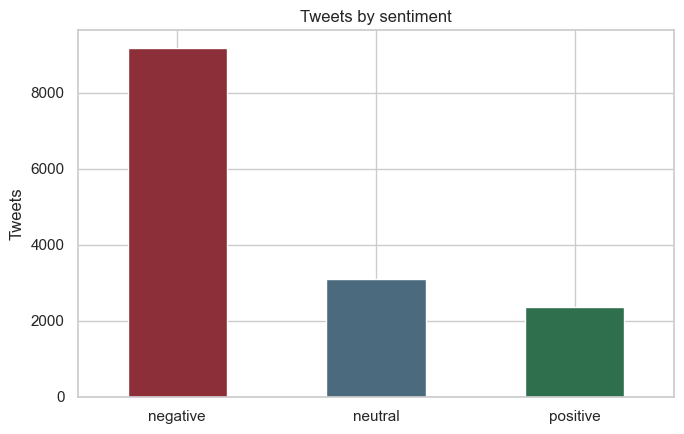

,tweets,percent
airline_sentiment,,
negative,9178,62.7
neutral,3099,21.2
positive,2363,16.1


In [2]:
tweets = pd.read_csv(DATA_PATH)
print("shape", tweets.shape)
print("missing text", int(tweets["text"].isna().sum()))
counts = tweets["airline_sentiment"].value_counts().reindex(LABELS)

fig, ax = plt.subplots(figsize=(7, 4.5))
counts.plot.bar(ax=ax, color=["#8c2f39", "#4c6a7d", "#2f6f4e"], rot=0)
ax.set_title("Tweets by sentiment")
ax.set_xlabel("")
ax.set_ylabel("Tweets")
fig.tight_layout()
plt.show()

share = (counts / counts.sum() * 100).round(1)
pd.DataFrame({"tweets": counts, "percent": share})


The classes are uneven. 9,178 tweets are negative (62.7%), 3,099 are neutral (21.2%), and 2,363 are positive (16.1%). No tweet text is missing.

A model can look accurate by calling most tweets negative. The scores below therefore include precision, recall, and F1 for each class, not accuracy alone. The split is stratified so the test set keeps this same mix.


## 3. Text preprocessing

Each tweet is put through the same steps.

1. Lower case, so `Cancelled` and `cancelled` match.
2. URLs and `@handles` are removed. The handle is the airline name, and leaving it in would let the model use which airline was mentioned instead of what was said.
3. Punctuation and digits are removed.
4. The remaining words are split on whitespace.
5. Stop words (`the`, `and`, `was`) are removed, and words of one or two letters are dropped.
6. Each word is lemmatised so `flights` and `flight` count as the same word.

Forty-three tweets become empty because they were only a handle, a link, or stop words. They stay in the data. An empty tweet is a real input the model has to face.


In [3]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [
        LEMMATIZER.lemmatize(token)
        for token in text.split()
        if token not in STOPWORDS and len(token) > 2
    ]
    return " ".join(tokens)


tweets["clean_text"] = tweets["text"].map(clean_text)
print("empty after cleaning", int((tweets["clean_text"].str.len() == 0).sum()))
tweets[["text", "clean_text", "airline_sentiment"]].head(3)


empty after cleaning 43


,text,clean_text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,said,neutral
1,@VirginAmerica plus you've added commercials to the experience... tacky.,plus added commercial experience tacky,positive
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,today must mean need take another trip,neutral


## 4. TF-IDF

A count vector would treat every word as equally informative, including words that appear in almost every tweet. TF-IDF multiplies how often a word appears in a tweet by how rare that word is across the whole training set. Words that show up everywhere are scaled down. Words that show up in fewer tweets keep more weight.

The vectorizer keeps the 5,000 most informative unigrams and bigrams, and it ignores a term that appears in only one training tweet. Bigrams matter here because `cancelled flight` is a different signal from the two words apart. The vectorizer is fit on the training text only, so the test tweets cannot influence the vocabulary.


In [4]:
features = tweets["clean_text"]
target = tweets["airline_sentiment"]
raw_text = tweets["text"]

X_train, X_test, y_train, y_test, raw_train, raw_test = train_test_split(
    features,
    target,
    raw_text,
    test_size=0.2,
    random_state=42,
    stratify=target,
)
print("train", len(X_train), "test", len(X_test))

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
print("features", X_train_tfidf.shape[1])


train 11712 test 2928


features 5000


## 5. Models

The training set is 80% of the tweets (11,712) and the test set is 20% (2,928).

Naive Bayes treats the weighted words as independent evidence for a class. It is a standard first model for text. Logistic regression learns one weight per word for each class, so it can down-weight a word that Naive Bayes would over-trust. Both see the same TF-IDF matrix.


In [5]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
}
predictions = {}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    predictions[name] = model.predict(X_test_tfidf)
    print(name, "accuracy", round(accuracy_score(y_test, predictions[name]), 3))
    print(classification_report(y_test, predictions[name], digits=3))


Naive Bayes accuracy 0.737
              precision    recall  f1-score   support

    negative      0.727     0.983     0.836      1835
     neutral      0.724     0.258     0.380       620
    positive      0.851     0.410     0.553       473

    accuracy                          0.737      2928
   macro avg      0.767     0.550     0.590      2928
weighted avg      0.747     0.737     0.694      2928



Logistic Regression accuracy 0.784
              precision    recall  f1-score   support

    negative      0.805     0.941     0.867      1835
     neutral      0.666     0.479     0.557       620
    positive      0.810     0.577     0.674       473

    accuracy                          0.784      2928
   macro avg      0.760     0.666     0.700      2928
weighted avg      0.776     0.784     0.770      2928



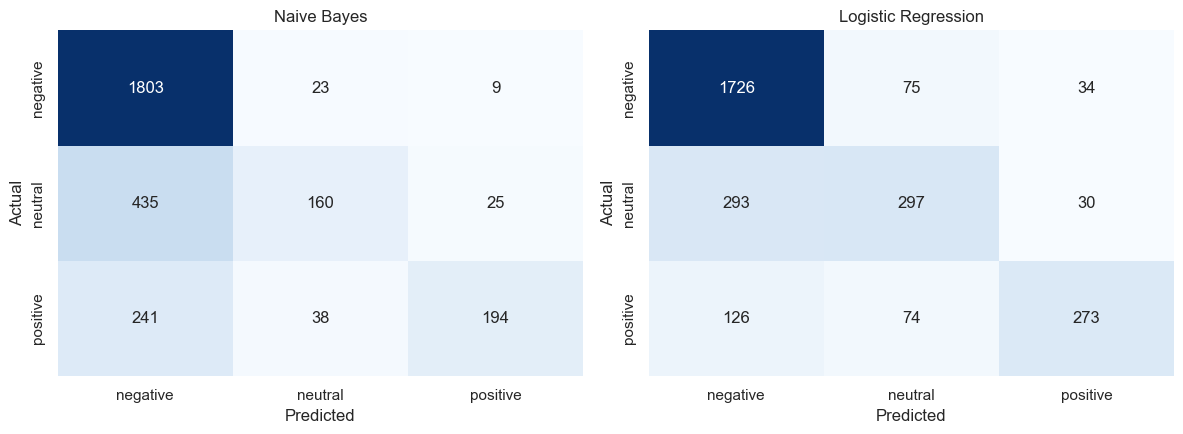

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, predicted) in zip(axes, predictions.items()):
    matrix = confusion_matrix(y_test, predicted, labels=LABELS)
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=LABELS, yticklabels=LABELS, ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.tight_layout()
plt.show()


Logistic regression is the stronger model. Accuracy is 78.4% against 73.7% for Naive Bayes. Weighted F1 is 0.770 against 0.694, and macro F1, which gives the three classes equal weight, is 0.700 against 0.590.

Naive Bayes finds almost every negative tweet (recall 0.983) by labelling neutral and positive tweets as negative. Neutral recall is 0.258 and positive recall is 0.410. On the confusion matrix, 435 of 620 neutral tweets and 241 of 473 positive tweets are called negative.

Logistic regression still prefers the negative class, but less so. Negative recall is 0.941, neutral recall is 0.479, and positive recall is 0.577. Neutral remains the hardest class: its F1 is 0.557, against 0.867 for negative and 0.674 for positive.


## 6. Words behind each class


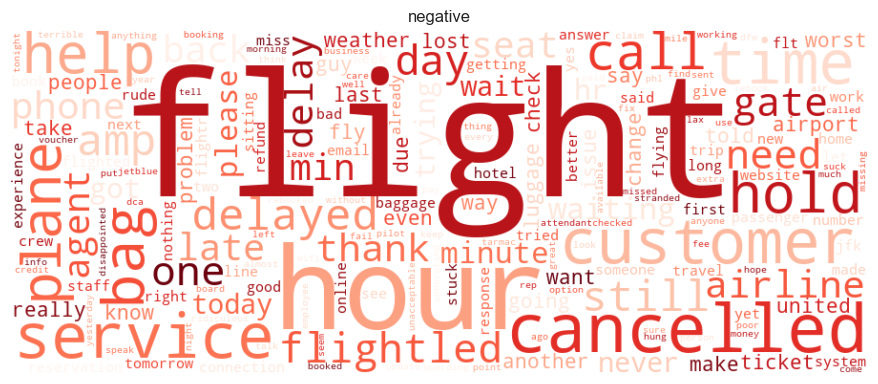

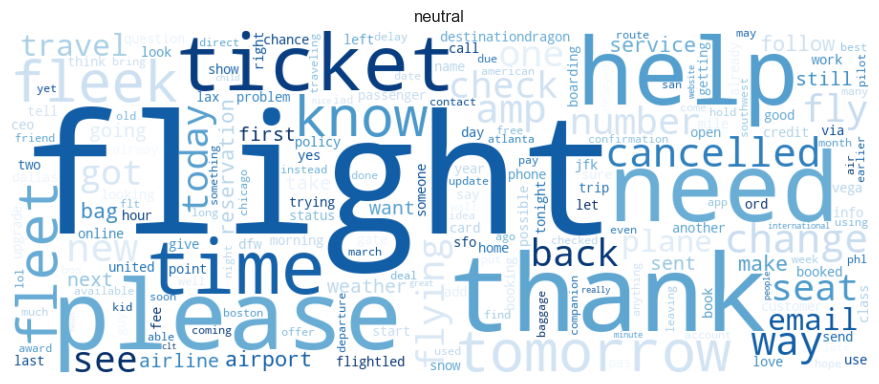

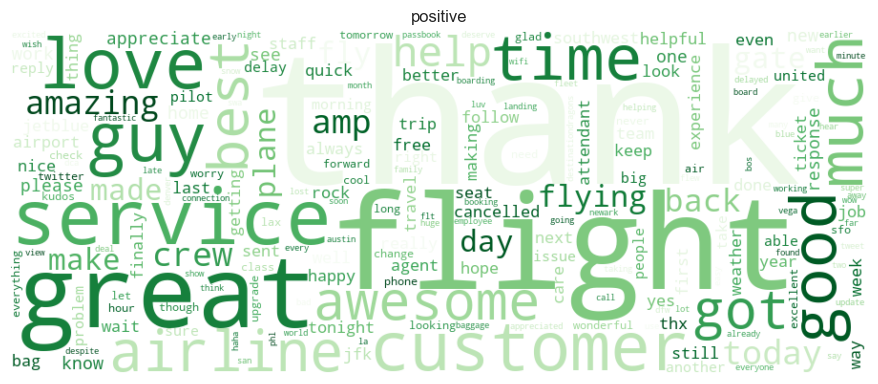

In [7]:
colors = {"negative": "Reds", "neutral": "Blues", "positive": "Greens"}
for label in LABELS:
    text = " ".join(tweets.loc[tweets["airline_sentiment"] == label, "clean_text"])
    cloud = WordCloud(
        width=900, height=360, background_color="white", colormap=colors[label],
        collocations=False,
    ).generate(text)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.imshow(cloud, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(label)
    fig.tight_layout()
    plt.show()


The negative cloud is dominated by `flight`, then `hour`, `cancelled`, `service`, and `bag`. The complaints are about delays, cancellations, and luggage, not about a vague bad feeling.

The positive cloud is `thanks`, `thank`, `great`, and `love`, with `flight` still present because people are talking about a flight they liked. The neutral cloud is requests: `please`, `need`, `help`, and `ticket`. Neutral tweets often ask for something rather than praise or blame, which is why they are easy to push into the negative class.


## 7. Five mistakes


In [8]:
best_name = "Logistic Regression"
review = pd.DataFrame({
    "tweet": raw_test,
    "actual": y_test,
    "predicted": predictions[best_name],
})
mistakes = review.loc[review["actual"].to_numpy() != review["predicted"].to_numpy()].head(5)
mistakes


,tweet,actual,predicted
2998,@united past,neutral,negative
7719,@JetBlue would you say a delay is more likely? Thanks so much.,positive,negative
4006,@united This link in your tweet goes to someone's internal email -&gt; http://t.co/ZksX79itdN...... Probably one of your 3rd party IT co...,neutral,negative
4686,@SouthwestAir When will the flight resume? I don's see it in the open schedule. :/,negative,neutral
8985,@USAirways Well I did miss it. But gate agents had rebooked boarding pass waiting when I landed. Time for lunch &amp; a beverage. Easy c...,positive,negative


These are the first five test tweets that logistic regression got wrong.

1. `@united past` is neutral and was called negative. After cleaning, almost no words remain. With nothing to read, the model falls back to the majority class.

2. `@JetBlue would you say a delay is more likely? Thanks so much.` is positive and was called negative. `delay` is a complaint word in this file. The tweet is only a polite question, and the thanks is not enough to outweigh `delay`.

3. The United tweet about a link that opens someone's internal email is neutral and was called negative. It reports a broken link. There is no insult in it, but the model has learned that a problem report is a complaint.

4. `@SouthwestAir When will the flight resume? I don's see it in the open schedule. :/` is negative and was called neutral. The complaint is phrased as a question, and the frown was stripped out with the punctuation, so the remaining words look like a schedule request.

5. The US Airways tweet that begins `Well I did miss it` and then praises the gate agents is positive and was called negative. The customer missed the flight and then described a good recovery. `miss` pulls the tweet toward negative, and the model does not really read the turn in the second sentence.

The shared pattern is context. A single loaded word (`delay`, `miss`, a problem being reported) outweighs the rest of a short tweet, and sarcasm or a frown never reaches the model because punctuation was removed.


## 8. Conclusion

Logistic regression is the model to keep. It is more accurate than Naive Bayes, and it is less willing to call every tweet a complaint. Naive Bayes is simpler, but its 73.7% accuracy is mostly the negative class.

An airline social-care team could use the logistic model to queue likely complaints for an agent and leave neutral questions in a slower queue. It should not send an automatic refund or an automatic apology. The errors above are exactly the tweets a script would mishandle: a polite question that contains the word `delay`, a factual bug report, and a customer who is thanking an agent for fixing a missed flight.
